Cell 1 - Imports and paths

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

BASE_DIR = Path(r"C:\Users\NickK\OneDrive\Υπολογιστής\github\kaggle_store_sales_forecasting")
PROCESSED_DIR = BASE_DIR / "data" / "processed"

train = pd.read_csv(PROCESSED_DIR / "train_features.csv")
test = pd.read_csv(PROCESSED_DIR / "test_features.csv")

train["date"] = pd.to_datetime(train["date"])
test["date"] = pd.to_datetime(test["date"])

print(train.shape)
print(test.shape)

(3000888, 21)
(28512, 20)


Cell 2 - Select features

In [2]:
target = "sales"

features = [
    "store_nbr",
    "family",
    "onpromotion",
    "year",
    "month",
    "day",
    "quarter",
    "week",
    "day_of_week",
    "is_weekend",
    "city",
    "state",
    "type",
    "cluster",
    "dcoilwtico",
    "is_payday",
    "is_national_holiday",
    "earthquake_period"
]

X = train[features]
y = np.log1p(train[target])
X_test = test[features]

Cell 3 - One-hot encoding

In [3]:
X = pd.get_dummies(X, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

X, X_test = X.align(X_test, join="left", axis=1, fill_value=0)

print(X.shape)
print(X_test.shape)

(3000888, 86)
(28512, 86)


Cell 4 - Time split

In [4]:
split_date = "2017-01-01"

train_mask = train["date"] < split_date
valid_mask = train["date"] >= split_date

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]

X_valid = X.loc[valid_mask]
y_valid_original = train.loc[valid_mask, target]

print(X_train.shape)
print(X_valid.shape)

(2596374, 86)
(404514, 86)


Cell 5 - Import XGBoost

In [5]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_log_error

Cell 6 - Train first XGBoost model

In [6]:
xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost model trained.")

XGBoost model trained.


Cell 7 - Validation RMSLE

In [7]:
valid_log_preds = xgb_model.predict(X_valid)

valid_preds = np.expm1(valid_log_preds)
valid_preds = np.maximum(valid_preds, 0)

rmsle = np.sqrt(
    mean_squared_log_error(
        y_valid_original,
        valid_preds
    )
)

print("Validation RMSLE:", rmsle)

Validation RMSLE: 0.6839062179246476


Cell 8

In [8]:
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": xgb_model.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values(
        "importance",
        ascending=False
    )
)

feature_importance.head(20)

,feature,importance
25,family_GROCERY I,0.097725
20,family_CLEANING,0.072297
16,family_BEVERAGES,0.066389
41,family_POULTRY,0.057932
22,family_DELI,0.057557
21,family_DAIRY,0.056090
37,family_MEATS,0.054910
18,family_BREAD/BAKERY,0.053674
38,family_PERSONAL CARE,0.038633
23,family_EGGS,0.035374


Cell 9

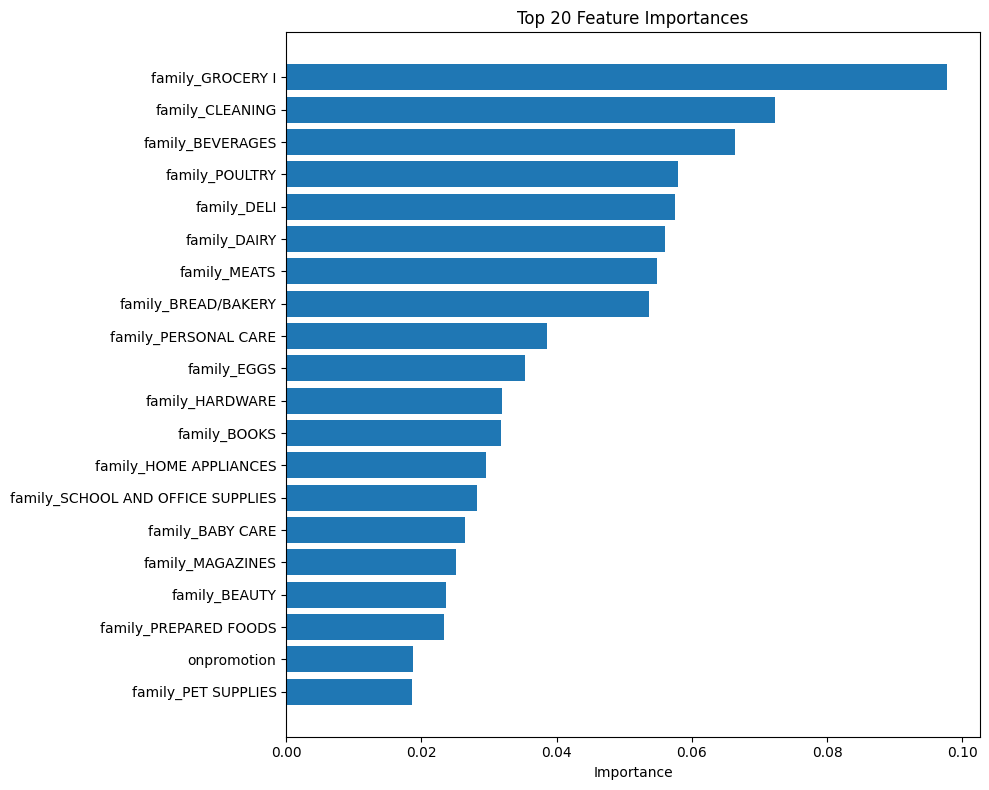

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))

plt.barh(
    feature_importance.head(20)["feature"][::-1],
    feature_importance.head(20)["importance"][::-1]
)

plt.title("Top 20 Feature Importances")
plt.xlabel("Importance")

plt.tight_layout()
plt.show()

Cell 10

In [10]:
test_log_preds = xgb_model.predict(X_test)

test_preds = np.expm1(test_log_preds)

test_preds = np.maximum(
    test_preds,
    0
)

submission = pd.DataFrame({
    "id": test["id"],
    "sales": test_preds
})

submission.head()

,id,sales
0,3000888,7.543648
1,3000889,0.113301
2,3000890,7.889906
3,3000891,2078.194092
4,3000892,0.077186


Cell 11

In [11]:
submission.to_csv(
    BASE_DIR / "submission_xgboost.csv",
    index=False
)

print("Submission saved.")

Submission saved.
